<center><h2>Walmart Sales Forecasting </h2></center>

## Import Libraries

In [21]:
from pathlib import Path
import re, json, time, math, logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from prophet import Prophet

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)
sns.set_theme(style="whitegrid")
np.random.seed(42)

In [27]:
FAST_MODE = True

DATA_DIR = Path(r"C:\Users\hp\Downloads\m5-forecasting-accuracy")
OUTPUT_DIR = Path("./outputs"); OUTPUT_DIR.mkdir(exist_ok=True)

HORIZON = 28
N_FOLDS = 3 if FAST_MODE else 6        # rolling-origin backtest windows of 28 days each
N_STORES = 2 if FAST_MODE else 5       # first N stores (sorted); all 3 categories are used
STAT_HISTORY = 730                     # days of history given to ARIMA/SARIMA/Holt-Winters/Prophet
GBM_ORIGIN_STEP = 7                    # ML training origins every 7 days
FIRST_GBM_ORIGIN = 60

FILES = {"calendar": DATA_DIR / "calendar.csv",
         "sales": DATA_DIR / "sales_train_evaluation.csv"}
missing = [str(p) for p in FILES.values() if not p.exists()]
if missing:
    raise FileNotFoundError("Missing files: " + ", ".join(missing))

## Load Data

In [29]:
hdr = pd.read_csv(FILES["sales"], nrows=0).columns
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
day_cols = sorted([c for c in hdr if re.fullmatch(r"d_\d+", c)], key=lambda x: int(x[2:]))
sales = pd.read_csv(FILES["sales"], dtype={c: "int32" for c in day_cols})
calendar = pd.read_csv(FILES["calendar"], parse_dates=["date"])
calendar["dnum"] = calendar["d"].str[2:].astype(int)
calendar = calendar.sort_values("dnum").reset_index(drop=True)

T = len(day_cols)                       # observed days (1941 in M5)
NCAL = len(calendar)                    # observed + 28 future days (1969 in M5)
assert NCAL >= T + HORIZON, "calendar must include the 28 future days"
assert sales["id"].duplicated().sum() == 0
print("Observed days:", T, "| calendar days:", NCAL)
print("Missing sales:", int(sales[day_cols].isna().sum().sum()),
      "| negative sales:", int((sales[day_cols] < 0).sum().sum()))

stores = sorted(sales["store_id"].unique())[:N_STORES]
sales = sales[sales["store_id"].isin(stores)]
state_by_store = sales[["store_id", "state_id"]].drop_duplicates().set_index("store_id")["state_id"].to_dict()

wide = sales.groupby(["store_id", "cat_id"])[day_cols].sum()
series_ids = [f"{s}__{c}" for s, c in wide.index]
S = len(series_ids)
Yv = wide.values.T.astype(float)        # shape (T, S)
hist_dates = pd.DatetimeIndex(calendar["date"].iloc[:T], freq="D")
Y = pd.DataFrame(Yv, index=hist_dates, columns=series_ids)
del sales
print("Series:", S, "|", series_ids)
print("Date range:", hist_dates.min().date(), "to", hist_dates.max().date())
Y.describe().T[["mean", "std", "min", "max"]]

Observed days: 1941 | calendar days: 1969
Missing sales: 0 | negative sales: 0
Series: 6 | ['CA_1__FOODS', 'CA_1__HOBBIES', 'CA_1__HOUSEHOLD', 'CA_2__FOODS', 'CA_2__HOBBIES', 'CA_2__HOUSEHOLD']
Date range: 2011-01-29 to 2016-05-22


,mean,std,min,max
CA_1__FOODS,2818.990726,701.442863,0.0,5016.0
CA_1__HOBBIES,459.599691,124.156370,0.0,953.0
CA_1__HOUSEHOLD,756.570840,260.881366,0.0,1665.0
CA_2__FOODS,1837.958269,599.407517,2.0,4502.0
CA_2__HOBBIES,335.064400,100.874319,0.0,762.0
CA_2__HOUSEHOLD,824.604843,287.771664,0.0,1881.0


In [39]:
cal_dates = pd.DatetimeIndex(calendar["date"])
DOW = cal_dates.dayofweek.values
MONTH = cal_dates.month.values
DOM = cal_dates.day.values
EV = calendar[["event_name_1", "event_name_2"]].notna().any(axis=1).astype(int).values
snap_col = {"CA": "snap_CA", "TX": "snap_TX", "WI": "snap_WI"}
SNAP = np.column_stack([calendar[snap_col[state_by_store[sid.split("__")[0]]]].values for sid in series_ids]).astype(int)
SNAP_df = pd.DataFrame(SNAP, index=cal_dates, columns=series_ids)
print("Event days:", int(EV[:T].sum()), "| future calendar days:", NCAL - T)

Event days: 158 | future calendar days: 28


## 4. EDA, stationarity (ADF + KPSS) and decomposition


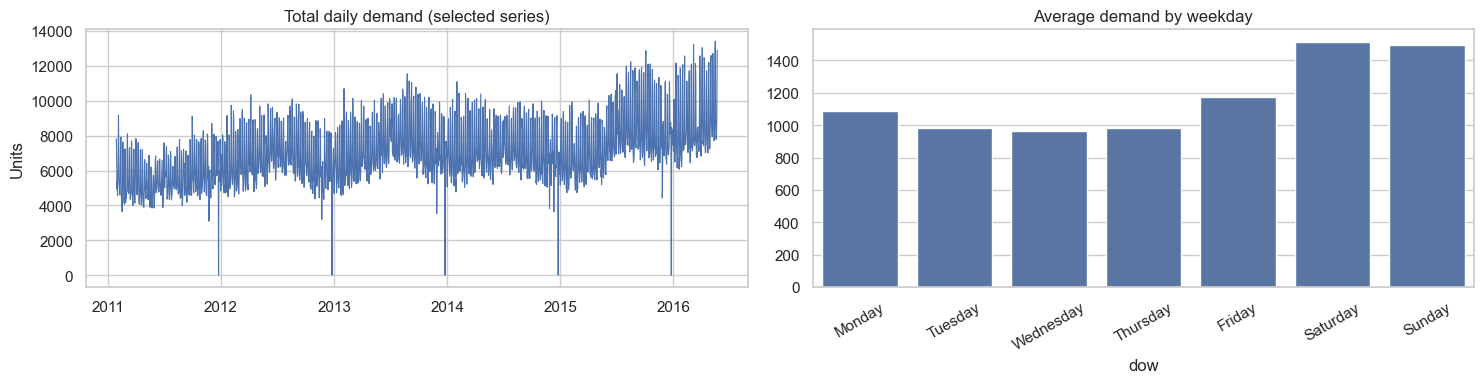

,ADF_p,KPSS_p,ADF_p_diff1,KPSS_p_diff1,ADF_p_seasonal_diff7,verdict_level
series,,,,,,
CA_1__FOODS,0.1849,0.01,0.0,0.1,0.0,non-stationary
CA_1__HOBBIES,0.0479,0.01,0.0,0.1,0.0,conflicting / trend-stationary
CA_1__HOUSEHOLD,0.5541,0.01,0.0,0.1,0.0,non-stationary
CA_2__FOODS,0.9706,0.01,0.0,0.1,0.0,non-stationary
CA_2__HOBBIES,0.1771,0.01,0.0,0.1,0.0,non-stationary
CA_2__HOUSEHOLD,0.6894,0.01,0.0,0.1,0.0,non-stationary


In [42]:
total = Y.sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(total.index, total.values, lw=.8); axes[0].set(title="Total daily demand (selected series)", ylabel="Units")
wk = Y.assign(dow=Y.index.day_name()).groupby("dow").mean().mean(axis=1).reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
sns.barplot(x=wk.index, y=wk.values, ax=axes[1]); axes[1].set(title="Average demand by weekday")
axes[1].tick_params(axis="x", rotation=30); plt.tight_layout(); plt.show()

rows = []
for sid in series_ids:
    y = Y[sid].values
    adf_p = adfuller(y, autolag="AIC")[1]
    kpss_p = kpss(y, regression="c", nlags="auto")[1]
    dy = np.diff(y, n=1); d7 = y[7:] - y[:-7]
    rows.append({"series": sid, "ADF_p": adf_p, "KPSS_p": kpss_p,
                 "ADF_p_diff1": adfuller(dy)[1], "KPSS_p_diff1": kpss(dy, nlags="auto")[1],
                 "ADF_p_seasonal_diff7": adfuller(d7)[1]})
stationarity = pd.DataFrame(rows).set_index("series")
stationarity["verdict_level"] = np.where((stationarity.ADF_p < .05) & (stationarity.KPSS_p >= .05), "stationary",
                                np.where((stationarity.ADF_p >= .05) & (stationarity.KPSS_p < .05), "non-stationary",
                                         "conflicting / trend-stationary"))
display(stationarity.round(4))
stationarity.to_csv(OUTPUT_DIR / "stationarity_tests.csv")

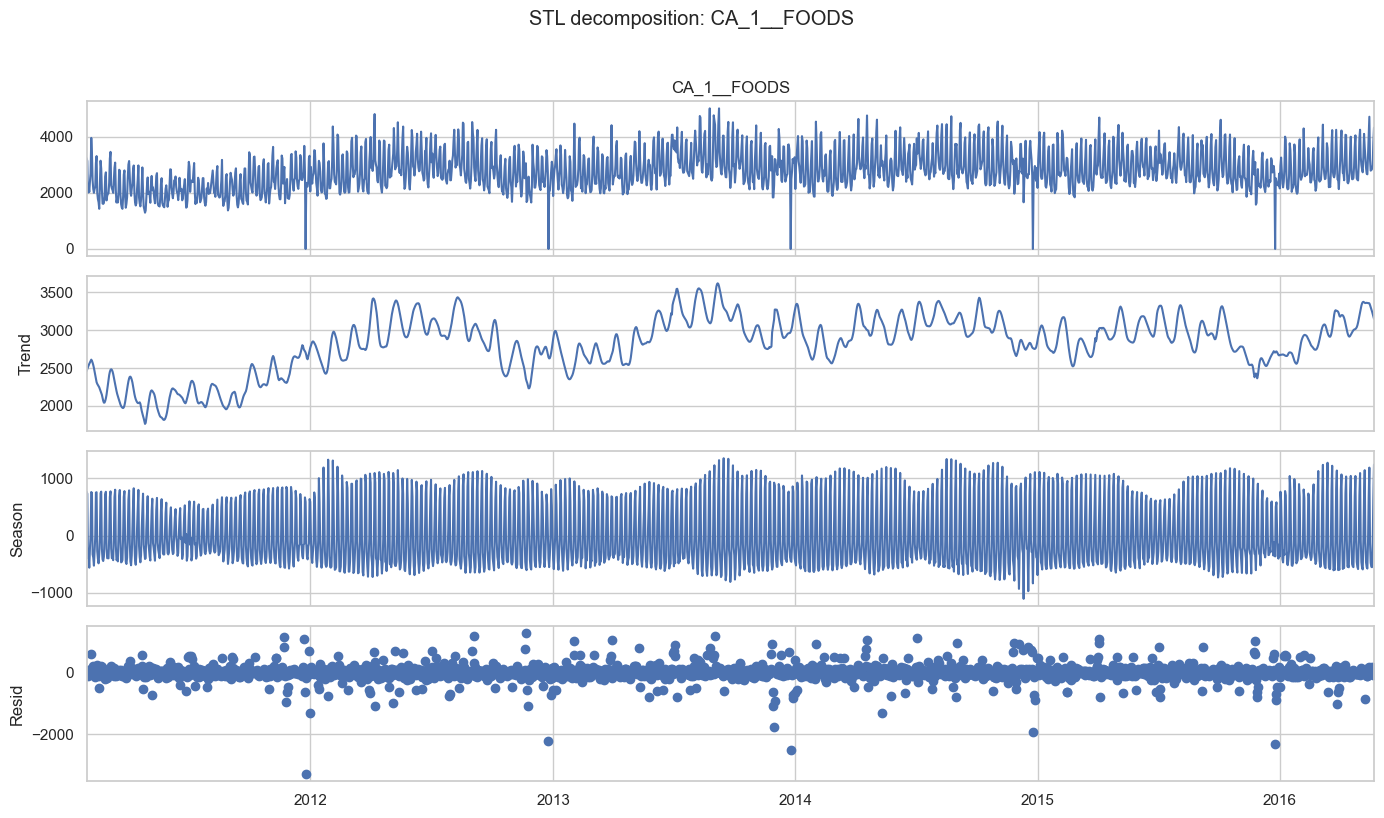

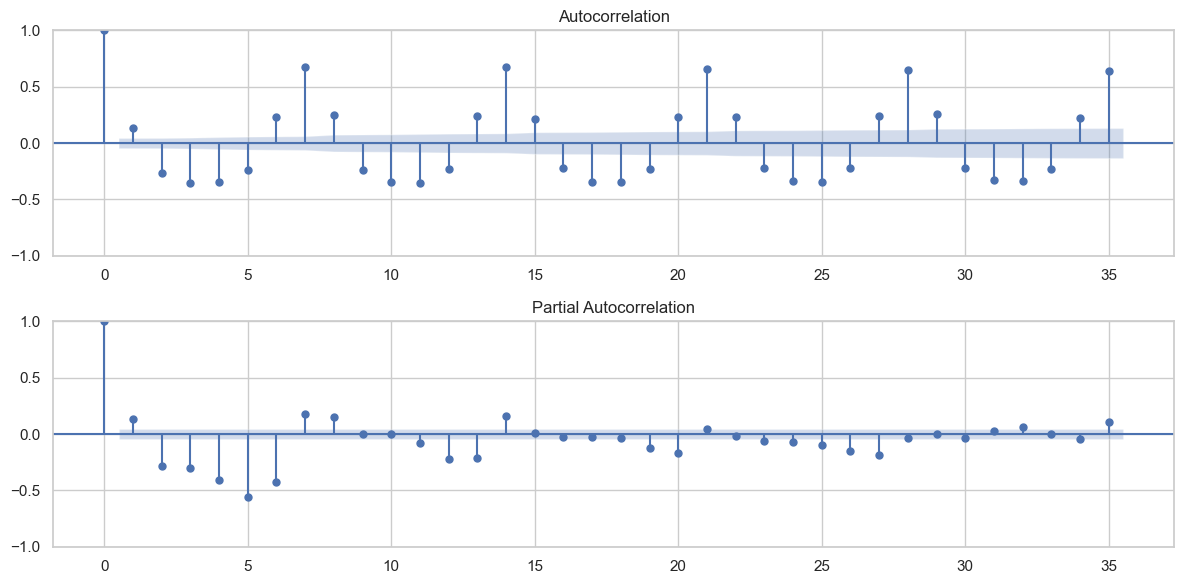

Reading: strong spikes at lags 7, 14, 21 in the ACF confirm weekly seasonality -> use seasonal period 7.


In [44]:
rep = Y.sum().idxmax()
stl = STL(Y[rep], period=7, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(14, 8); fig.suptitle(f"STL decomposition: {rep}", y=1.02); plt.tight_layout(); plt.show()

d = Y[rep].diff().dropna()
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
plot_acf(d, lags=35, ax=ax[0]); plot_pacf(d, lags=35, method="ywm", ax=ax[1]); plt.tight_layout(); plt.show()
print("Reading: strong spikes at lags 7, 14, 21 in the ACF confirm weekly seasonality -> use seasonal period 7.")

## Metrics

In [47]:
def wape(a, f):
    a = np.asarray(a, float); f = np.asarray(f, float)
    return np.abs(f - a).sum() / max(a.sum(), 1e-9)

def metrics(a, f):
    a = np.asarray(a, float); f = np.asarray(f, float); e = f - a
    return {"WAPE": np.abs(e).sum() / max(a.sum(), 1e-9),
            "Bias": e.sum() / max(a.sum(), 1e-9),
            "MAE": np.abs(e).mean(),
            "RMSE": np.sqrt((e ** 2).mean()),
            "sMAPE": np.mean(2 * np.abs(e) / (np.abs(a) + np.abs(f) + 1e-8))}

## Statistical Model Fitting

In [54]:
## select historical data
def get_hist(series_id, forecast_origin):

    # Find the last date available for training
    end_position = forecast_origin + 1

    # Select the maximum historical period
    start_position = end_position - STAT_HISTORY

    # Prevent negative starting positions
    if start_position < 0:
        start_position = 0

    # Extract historical sales for the selected series
    ## Training model with most recent data
    historical_sales = Y[series_id].iloc[start_position:end_position]

    return historical_sales

## 1. Seasonal Naive Forecasting (baseline model)
def fc_snaive(series_id, forecast_origin):

    # Get historical sales
    historical_sales = get_hist(series_id, forecast_origin)

    # Convert sales into a NumPy array
    sales_values = historical_sales.values

    # Store the sales from the previous 7 days
    last_week_sales = sales_values[-7:]

    # Generate forecasts for 28 days
    forecast = []

    for day in range(HORIZON):

        # Repeat the corresponding weekday's sales
        predicted_sales = last_week_sales[day % 7]

        forecast.append(predicted_sales)

    return np.array(forecast)

## 2.Holt-Winters Forecasting

def fc_holtwinters(series_id, forecast_origin):

    # Retrieve historical sales
    historical_sales = get_hist(series_id, forecast_origin)

    # Create the Holt-Winters model
    model = ExponentialSmoothing(historical_sales,trend="add",damped_trend=True,seasonal="add",seasonal_periods=7)

    # Train the model
    fitted_model = model.fit()

    # Forecast the next 28 days
    forecast = fitted_model.forecast(HORIZON)

    return np.array(forecast)

## 3. ARIMA Forecasting

def fc_arima(series_id, forecast_origin):

    # Get historical sales
    historical_sales = get_hist(series_id, forecast_origin)

    # Create the ARIMA model
    model = ARIMA(historical_sales,order=(2, 1, 2))

    # Train the model
    fitted_model = model.fit()

    # Forecast the next 28 days
    forecast = fitted_model.forecast(steps=HORIZON)

    return np.array(forecast)

## 4.SARIMA Forecasting

def fc_sarima(series_id, forecast_origin):

    # Retrieve historical sales
    historical_sales = get_hist(series_id, forecast_origin)

    # Define the SARIMA model
    model = SARIMAX( historical_sales,order=(1, 1, 1), seasonal_order=(1, 1, 1, 7),enforce_stationarity=False,
        enforce_invertibility=False)

    # Train the model
    fitted_model = model.fit(disp=False, maxiter=100 )

    # Predict the next 28 days
    forecast = fitted_model.forecast(steps=HORIZON)

    return np.array(forecast)

## 5. Prophet Forecasting

def fc_prophet(series_id, forecast_origin, cps=0.05):

    # Step 1: Get historical sales
    historical_sales = get_hist(series_id, forecast_origin)

    # Step 2: Find the series position
    series_position = series_ids.index(series_id)

    # Step 3: Prepare historical data
    training_data = pd.DataFrame()

    training_data["ds"] = historical_sales.index
    training_data["y"] = historical_sales.values

    # Add external variables
    start_position = forecast_origin + 1 - len(historical_sales)
    end_position = forecast_origin + 1

    training_data["event"] = EV[start_position:end_position]
    training_data["snap"] = SNAP[start_position:end_position, series_position]

    # Step 4: Prepare future dates
    future_dates = cal_dates[
        forecast_origin + 1 : forecast_origin + 1 + HORIZON
    ]

    future_data = pd.DataFrame()
    future_data["ds"] = future_dates

    # Add future external variables
    future_data["event"] = EV[
        forecast_origin + 1 : forecast_origin + 1 + HORIZON
    ]

    future_data["snap"] = SNAP[
        forecast_origin + 1 : forecast_origin + 1 + HORIZON,
        series_position
    ]

    # Step 5: Create the Prophet model
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        changepoint_prior_scale=cps
    )

    # Step 6: Add external variables
    model.add_regressor("event")
    model.add_regressor("snap")

    # Step 7: Train the model
    model.fit(training_data)

    # Step 8: Generate predictions
    predictions = model.predict(future_data)

    return predictions["yhat"].values

## ML Model Fitting

In [56]:
FEATS_BASE = ["h", "dow", "month", "dom", "event", "snap", "sw1", "sw2", "sw3", "sw4",
              "lag0", "roll7", "roll14", "l364"]

FEATS_LGB = FEATS_BASE + ["series_code"]
def build_rows(origins):

    # Store all generated training data
    all_rows = []

    # Process each historical forecast origin
    for t in origins:

        # Calculate average sales for the previous 28, 7 and 14 days
        average_28 = Yv[t - 27:t + 1].mean(axis=0)
        average_7 = Yv[t - 6:t + 1].mean(axis=0)
        average_14 = Yv[t - 13:t + 1].mean(axis=0)

        # Avoid division by zero while normalizing sales
        sales_scale = np.maximum(average_28, 1.0)

        # Generate features for the next 28 days
        for h in range(1, HORIZON + 1):

            # Find the date we want to predict
            target_date = t + h

            # Find sales from the same weekday in the previous week
            previous_week_date = target_date - 7 * math.ceil(h / 7)

            # Get sales from approximately one year earlier
            previous_year_date = target_date - 364

            if previous_year_date >= 0:
                previous_year_sales = Yv[previous_year_date]
            else:
                previous_year_sales = average_28

            # Get actual sales for the target date
            if target_date < T:
                actual_sales = Yv[target_date] / sales_scale
            else:
                actual_sales = np.full(S, np.nan)

            # Create a table containing features
            new_rows = pd.DataFrame({

                "origin": t,

                "tgt_idx": target_date,

                "series_idx": np.arange(S),

                "h": h,

                "dow": DOW[target_date],

                "month": MONTH[target_date],

                "dom": DOM[target_date],

                "event": EV[target_date],

                "snap": SNAP[target_date],

                "sw1": Yv[previous_week_date] / sales_scale,

                "sw2": Yv[previous_week_date - 7] / sales_scale,

                "sw3": Yv[previous_week_date - 14] / sales_scale,

                "sw4": Yv[previous_week_date - 21] / sales_scale,

                "lag0": Yv[t] / sales_scale,

                "roll7": average_7 / sales_scale,

                "roll14": average_14 / sales_scale,

                "l364": previous_year_sales / sales_scale,

                "series_code": np.arange(S),

                "scale": sales_scale,

                "target": actual_sales

            })

            # Add the newly created rows
            all_rows.append(new_rows)

    # Combine all generated rows into one training dataset
    final_data = pd.concat(all_rows, ignore_index=True)

    return final_data

# Record the starting time
start_time = time.time()

# Generate training rows from historical forecast origins
forecast_origins = range(
    FIRST_GBM_ORIGIN,
    T - 1,
    GBM_ORIGIN_STEP
)

ROWS = build_rows(forecast_origins)

# Convert series_code into a categorical variable
ROWS["series_code"] = ROWS["series_code"].astype("category")

# Calculate execution time
execution_time = time.time() - start_time

print("ML training dataset shape:", ROWS.shape)
print("Time taken:", round(execution_time, 2), "seconds")

def _train_mask(forecast_origin):

    # Select only rows whose target dates are
    # on or before the current forecast origin
    historical_rows = ROWS["tgt_idx"] <= forecast_origin

    # Remove rows where actual sales are unavailable
    available_targets = ROWS["target"].notna()

    # Combine both conditions
    training_rows = historical_rows & available_targets

    return training_rows
    
## preparing future prediction rows 
def _pred_rows(forecast_origin):

    # Generate feature rows for the current forecast origin
    prediction_data = build_rows([forecast_origin])

    # Ensure the series_code categories match the training dataset
    prediction_data["series_code"] = pd.Categorical(
        prediction_data["series_code"],
        categories=ROWS["series_code"].cat.categories
    )

    return prediction_data
    
## LightGBM model configuration
LGB_BASE = {

    "objective": "regression","learning_rate": 0.05, "n_estimators": 300,"num_leaves": 15,"min_child_samples": 20,
    "subsample": 0.8,"subsample_freq": 1,   "colsample_bytree": 0.8, "random_state": 42, "n_jobs": -1,"verbose": -1
}

## Training LightGBM Model

def fc_lgbm(forecast_origin, params=None):

    # Step 1: Copy the default model settings
    model_parameters = LGB_BASE.copy()

    # Step 2: Apply additional parameters if provided
    if params is not None:
        model_parameters.update(params)

    # Step 3: Select valid historical training data
    training_mask = _train_mask(forecast_origin)
    training_data = ROWS[training_mask]

    # Step 4: Create the LightGBM model
    model = lgb.LGBMRegressor(**model_parameters)

    # Step 5: Train the model
    model.fit(
        training_data[FEATS_LGB],
        training_data["target"]
    )

    # Step 6: Prepare future prediction data
    prediction_data = _pred_rows(forecast_origin)

    # Step 7: Predict normalized sales
    normalized_predictions = model.predict(
        prediction_data[FEATS_LGB]
    )

    # Step 8: Remove negative predictions
    normalized_predictions = np.maximum(
        normalized_predictions, 0
    )

    # Step 9: Convert predictions back to actual sales scale
    actual_predictions = (
        normalized_predictions *
        prediction_data["scale"].values
    )

    # Step 10: Arrange predictions by series and forecast day
    final_predictions = actual_predictions.reshape(
        HORIZON, S
    ).T

    return final_predictions

## Training Random Forest Model

def fc_rf(forecast_origin, params=None):

    # Step 1: Define default Random Forest parameters
    model_parameters = {

        "n_estimators": 200,

        "min_samples_leaf": 5,

        "max_features": 0.6,

        "n_jobs": -1,

        "random_state": 42
    }

    # Step 2: Update parameters if provided
    if params is not None:
        model_parameters.update(params)

    # Step 3: Get historical training data
    training_mask = _train_mask(forecast_origin)
    training_data = ROWS[training_mask]

    # Step 4: Create the Random Forest model
    model = RandomForestRegressor(**model_parameters)

    # Step 5: Train the model
    model.fit(
        training_data[FEATS_BASE],
        training_data["target"]
    )

    # Step 6: Prepare future prediction data
    prediction_data = _pred_rows(forecast_origin)

    # Step 7: Predict normalized sales
    normalized_predictions = model.predict(
        prediction_data[FEATS_BASE]
    )

    # Step 8: Remove negative predictions
    normalized_predictions = np.maximum(
        normalized_predictions, 0
    )

    # Step 9: Convert predictions into actual sales scale
    actual_predictions = (
        normalized_predictions *
        prediction_data["scale"].values
    )

    # Step 10: Arrange the predictions
    final_predictions = actual_predictions.reshape(
        HORIZON, S
    ).T

    return final_predictions

ML training dataset shape: (45192, 20)
Time taken: 6.31 seconds


## Backtest Design and Parameter Tuning

In [68]:

# ============================================================
# 1. CORRECT ARIMA AND SARIMA FORECASTING FUNCTIONS
# ============================================================

def fc_arima(sid, o, order=(2, 1, 2), **kwargs):

    historical_data = get_hist(sid, o)

    model = ARIMA(
        historical_data,
        order=order
    )

    fitted_model = model.fit()

    predictions = fitted_model.forecast(HORIZON)

    return np.asarray(predictions)


def fc_sarima(
    sid,
    o,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    **kwargs
):

    historical_data = get_hist(sid, o)

    model = SARIMAX(
        historical_data,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(
        disp=False,
        maxiter=100
    )

    predictions = fitted_model.forecast(HORIZON)

    return np.asarray(predictions)


# ============================================================
# 2. GENERATE BACKTESTING ORIGINS
# ============================================================

last_origin = T - 1 - HORIZON

origins = []

for j in range(N_FOLDS):

    current_origin = last_origin - (HORIZON * j)

    origins.append(current_origin)

origins.reverse()

# Tuning period comes before the first backtesting fold
tune_origin = origins[0] - HORIZON

print("Backtest origins:")

for origin in origins:
    print(cal_dates[origin].date())

print("\nTuning origin:", cal_dates[tune_origin].date())


# ============================================================
# 3. EXTRACT ACTUAL SALES FOR A 28-DAY WINDOW
# ============================================================

def actual_window(forecast_origin):

    start_date = forecast_origin + 1

    end_date = start_date + HORIZON

    actual_sales = Yv[start_date:end_date]

    return actual_sales.T


# ============================================================
# 4. DEFINE PARAMETER GRIDS
# ============================================================

SARIMA_GRID = [

    ((1, 1, 1), (1, 1, 1, 7)),

    ((2, 1, 1), (0, 1, 1, 7)),

    ((1, 1, 2), (1, 1, 1, 7))

]

ARIMA_GRID = [

    (1, 1, 1),

    (2, 1, 2),

    (3, 1, 2)

]

PROPHET_GRID = [

    0.01,

    0.05,

    0.3

]

LGB_GRID = [

    {
        "num_leaves": 15,
        "learning_rate": 0.05,
        "n_estimators": 300
    },

    {
        "num_leaves": 31,
        "learning_rate": 0.05,
        "n_estimators": 300
    },

    {
        "num_leaves": 15,
        "learning_rate": 0.03,
        "n_estimators": 600,
        "min_child_samples": 40
    }

]


# ============================================================
# 5. START PARAMETER TUNING
# ============================================================

start_time = time.time()

actual_sales = actual_window(tune_origin)

best = {
    "sarima": {},
    "arima": {}
}


# ============================================================
# 6. TUNE SARIMA AND ARIMA FOR EACH SERIES
# ============================================================

for series_position, series_id in enumerate(series_ids):

    print("\nTuning series:", series_id)

    # ---------------- SARIMA TUNING ----------------

    sarima_scores = []

    for order, seasonal_order in SARIMA_GRID:

        try:

            predictions = fc_sarima(
                series_id,
                tune_origin,
                order=order,
                seasonal_order=seasonal_order
            )

            error = wape(
                actual_sales[series_position],
                predictions
            )

            sarima_scores.append(
                (error, (order, seasonal_order))
            )

            print(
                "SARIMA:",
                order,
                seasonal_order,
                "| WAPE:",
                round(error, 4)
            )

        except Exception as error_message:

            print(
                "SARIMA configuration failed:",
                error_message
            )

    if not sarima_scores:

        raise RuntimeError(
            f"All SARIMA configurations failed for {series_id}."
        )

    best["sarima"][series_id] = min(
        sarima_scores,
        key=lambda x: x[0]
    )[1]


    # ---------------- ARIMA TUNING ----------------

    arima_scores = []

    for order in ARIMA_GRID:

        try:

            predictions = fc_arima(
                series_id,
                tune_origin,
                order=order
            )

            error = wape(
                actual_sales[series_position],
                predictions
            )

            arima_scores.append(
                (error, order)
            )

            print(
                "ARIMA:",
                order,
                "| WAPE:",
                round(error, 4)
            )

        except Exception as error_message:

            print(
                "ARIMA configuration failed:",
                error_message
            )

    if not arima_scores:

        raise RuntimeError(
            f"All ARIMA configurations failed for {series_id}."
        )

    best["arima"][series_id] = min(
        arima_scores,
        key=lambda x: x[0]
    )[1]


# ============================================================
# 7. TUNE PROPHET
# ============================================================

def pooled_wape_prophet(cps):

    all_predictions = []

    for series_id in series_ids:

        predictions = fc_prophet(
            series_id,
            tune_origin,
            cps=cps
        )

        all_predictions.append(predictions)

    all_predictions = np.vstack(all_predictions)

    return wape(
        actual_sales,
        all_predictions
    )


prophet_scores = {}

for cps in PROPHET_GRID:

    error = pooled_wape_prophet(cps)

    prophet_scores[cps] = error

    print(
        "Prophet configuration:",
        cps,
        "| WAPE:",
        round(error, 4)
    )


best["prophet_cps"] = min(
    prophet_scores,
    key=prophet_scores.get
)


# ============================================================
# 8. TUNE LIGHTGBM
# ============================================================

lgb_scores = {}

for combination_number, parameters in enumerate(LGB_GRID):

    predictions = fc_lgbm(
        tune_origin,
        parameters
    )

    error = wape(
        actual_sales,
        predictions
    )

    lgb_scores[combination_number] = error

    print(
        "LightGBM configuration:",
        combination_number,
        "| WAPE:",
        round(error, 4)
    )


best_lgb_index = min(
    lgb_scores,
    key=lgb_scores.get
)

best["lgbm"] = LGB_GRID[best_lgb_index]


# ============================================================
# 9. DISPLAY TUNING RESULTS
# ============================================================

total_time = time.time() - start_time

print("\nTuning completed in", round(total_time, 2), "seconds")

print("\nBest ARIMA parameters:")
print(best["arima"])

print("\nBest SARIMA parameters:")
print(best["sarima"])

print("\nBest Prophet parameter:")
print(best["prophet_cps"])

print("\nBest LightGBM parameters:")
print(best["lgbm"])


# ============================================================
# 10. SAVE BEST PARAMETERS
# ============================================================

saved_parameters = {

    "sarima": {},

    "arima": {},

    "prophet_cps": best["prophet_cps"],

    "lgbm": best["lgbm"]

}

for series_id, parameters in best["sarima"].items():

    saved_parameters["sarima"][series_id] = [

        list(parameters[0]),

        list(parameters[1])

    ]


for series_id, parameters in best["arima"].items():

    saved_parameters["arima"][series_id] = list(parameters)


with open(OUTPUT_DIR / "tuned_parameters.json", "w") as file:

    json.dump(
        saved_parameters,
        file,
        indent=2
    )

print("\nBest parameters saved successfully!")


# ============================================================
# 11. DEFINE ALL FORECASTING MODELS
# ============================================================

MODELS = [

    "SeasonalNaive",

    "HoltWinters",

    "ARIMA",

    "SARIMA",

    "Prophet",

    "RandomForest",

    "LightGBM"

]


# ============================================================
# 12. GENERATE PREDICTIONS FOR EACH MODEL
# ============================================================

def predict_model(model_name, forecast_origin):

    # Machine learning models
    if model_name == "RandomForest":

        predictions = fc_rf(forecast_origin)

        return np.maximum(np.asarray(predictions, dtype=float), 0)


    if model_name == "LightGBM":

        predictions = fc_lgbm(
            forecast_origin,
            best["lgbm"]
        )

        return np.maximum(np.asarray(predictions, dtype=float), 0)


    # Statistical and Prophet models
    all_predictions = []

    for series_id in series_ids:

        if model_name == "SeasonalNaive":

            forecast = fc_snaive(
                series_id,
                forecast_origin
            )

        elif model_name == "HoltWinters":

            forecast = fc_holtwinters(
                series_id,
                forecast_origin
            )

        elif model_name == "ARIMA":

            forecast = fc_arima(
                series_id,
                forecast_origin,
                order=best["arima"][series_id]
            )

        elif model_name == "SARIMA":

            order, seasonal_order = best["sarima"][series_id]

            forecast = fc_sarima(
                series_id,
                forecast_origin,
                order=order,
                seasonal_order=seasonal_order
            )

        elif model_name == "Prophet":

            forecast = fc_prophet(
                series_id,
                forecast_origin,
                cps=best["prophet_cps"]
            )

        else:

            raise ValueError(
                "Unknown forecasting model: " + model_name
            )

        forecast = np.asarray(
            forecast,
            dtype=float
        ).reshape(-1)

        forecast = np.maximum(forecast, 0)

        all_predictions.append(forecast)

    return np.vstack(all_predictions)


# ============================================================
# 13. EXECUTE BACKTESTING
# ============================================================

records = []

runtime = {
    model_name: 0.0
    for model_name in MODELS
}


for fold_number, forecast_origin in enumerate(origins):

    print(
        "\nRunning fold:",
        fold_number + 1,
        "of",
        len(origins)
    )

    # Get actual sales for this fold
    actuals = actual_window(forecast_origin)

    forecast_dates = cal_dates[
        forecast_origin + 1:
        forecast_origin + 1 + HORIZON
    ]

    for model_name in MODELS:

        print("Running:", model_name)

        model_start_time = time.time()

        try:

            predictions = predict_model(
                model_name,
                forecast_origin
            )

            # Check forecast dimensions
            if predictions.shape != (S, HORIZON):

                raise ValueError(
                    f"Expected shape {(S, HORIZON)}, "
                    f"but received {predictions.shape}"
                )

            # Check actual sales dimensions
            if actuals.shape != (S, HORIZON):

                raise ValueError(
                    f"Unexpected actual-sales shape: {actuals.shape}"
                )

            # Check for invalid predictions
            if not np.isfinite(predictions).all():

                raise ValueError(
                    "Predictions contain NaN or infinite values."
                )

            # Store predictions and actual values
            for series_position, series_id in enumerate(series_ids):

                model_results = pd.DataFrame({

                    "fold": fold_number,

                    "origin_date": cal_dates[forecast_origin],

                    "series_id": series_id,

                    "date": forecast_dates,

                    "h": np.arange(1, HORIZON + 1),

                    "model": model_name,

                    "actual": actuals[series_position],

                    "forecast": predictions[series_position]

                })

                records.append(model_results)

            runtime[model_name] += (
                time.time() - model_start_time
            )

            print(model_name, "completed successfully.")

        except Exception as error_message:

            raise RuntimeError(
                f"Backtesting failed for {model_name}, "
                f"fold {fold_number + 1}: {error_message}"
            ) from error_message

    print(
        "Fold",
        fold_number + 1,
        "completed successfully."
    )


# ============================================================
# 14. CREATE BACKTESTING DATAFRAME
# ============================================================

bt = pd.concat(
    records,
    ignore_index=True
)

print("\nBACKTESTING COMPLETED SUCCESSFULLY")

print("\nBacktesting DataFrame shape:")
print(bt.shape)

print("\nBacktesting columns:")
print(bt.columns.tolist())

print("\nBacktesting preview:")

display(bt.head())


# ============================================================
# 15. VERIFY BACKTESTING RESULTS
# ============================================================

print("\nNumber of backtesting folds:")
print(bt["fold"].nunique())

print("\nNumber of forecasting models:")
print(bt["model"].nunique())

print("\nNumber of series:")
print(bt["series_id"].nunique())

print("\nRecords generated per model:")

display(
    bt.groupby("model").size().reset_index(
        name="number_of_records"
    )
)


# ============================================================
# 16. DISPLAY MODEL EXECUTION TIME
# ============================================================

runtime_table = pd.DataFrame({

    "model": list(runtime.keys()),

    "runtime_s": list(runtime.values())

})

print("\nModel execution time:")

display(runtime_table)


Backtest origins:
2016-02-28
2016-03-27
2016-04-24

Tuning origin: 2016-01-31

Tuning series: CA_1__FOODS
SARIMA: (1, 1, 1) (1, 1, 1, 7) | WAPE: 0.1043
SARIMA: (2, 1, 1) (0, 1, 1, 7) | WAPE: 0.1091
SARIMA: (1, 1, 2) (1, 1, 1, 7) | WAPE: 0.1058
ARIMA: (1, 1, 1) | WAPE: 0.1762
ARIMA: (2, 1, 2) | WAPE: 0.1068
ARIMA: (3, 1, 2) | WAPE: 0.1031

Tuning series: CA_1__HOBBIES
SARIMA: (1, 1, 1) (1, 1, 1, 7) | WAPE: 0.1078
SARIMA: (2, 1, 1) (0, 1, 1, 7) | WAPE: 0.1108
SARIMA: (1, 1, 2) (1, 1, 1, 7) | WAPE: 0.1045
ARIMA: (1, 1, 1) | WAPE: 0.1325
ARIMA: (2, 1, 2) | WAPE: 0.1324
ARIMA: (3, 1, 2) | WAPE: 0.1272

Tuning series: CA_1__HOUSEHOLD
SARIMA: (1, 1, 1) (1, 1, 1, 7) | WAPE: 0.0742
SARIMA: (2, 1, 1) (0, 1, 1, 7) | WAPE: 0.0745
SARIMA: (1, 1, 2) (1, 1, 1, 7) | WAPE: 0.0742
ARIMA: (1, 1, 1) | WAPE: 0.1919
ARIMA: (2, 1, 2) | WAPE: 0.1538
ARIMA: (3, 1, 2) | WAPE: 0.1415

Tuning series: CA_2__FOODS
SARIMA: (1, 1, 1) (1, 1, 1, 7) | WAPE: 0.0832
SARIMA: (2, 1, 1) (0, 1, 1, 7) | WAPE: 0.0833
SARIMA: (1

21:46:45 - cmdstanpy - INFO - Chain [1] start processing


ARIMA: (3, 1, 2) | WAPE: 0.2351


21:46:45 - cmdstanpy - INFO - Chain [1] done processing
21:46:45 - cmdstanpy - INFO - Chain [1] start processing
21:46:45 - cmdstanpy - INFO - Chain [1] done processing
21:46:46 - cmdstanpy - INFO - Chain [1] start processing
21:46:46 - cmdstanpy - INFO - Chain [1] done processing
21:46:46 - cmdstanpy - INFO - Chain [1] start processing
21:46:46 - cmdstanpy - INFO - Chain [1] done processing
21:46:46 - cmdstanpy - INFO - Chain [1] start processing
21:46:46 - cmdstanpy - INFO - Chain [1] done processing
21:46:47 - cmdstanpy - INFO - Chain [1] start processing
21:46:47 - cmdstanpy - INFO - Chain [1] done processing
21:46:47 - cmdstanpy - INFO - Chain [1] start processing


Prophet configuration: 0.01 | WAPE: 0.1213


21:46:47 - cmdstanpy - INFO - Chain [1] done processing
21:46:48 - cmdstanpy - INFO - Chain [1] start processing
21:46:48 - cmdstanpy - INFO - Chain [1] done processing
21:46:48 - cmdstanpy - INFO - Chain [1] start processing
21:46:48 - cmdstanpy - INFO - Chain [1] done processing
21:46:49 - cmdstanpy - INFO - Chain [1] start processing
21:46:49 - cmdstanpy - INFO - Chain [1] done processing
21:46:49 - cmdstanpy - INFO - Chain [1] start processing
21:46:49 - cmdstanpy - INFO - Chain [1] done processing
21:46:49 - cmdstanpy - INFO - Chain [1] start processing
21:46:50 - cmdstanpy - INFO - Chain [1] done processing


... (12 outputs left out)


Number of backtesting folds:
3

Number of forecasting models:
7

Number of series:
6

Records generated per model:


,model,number_of_records
0,ARIMA,504
1,HoltWinters,504
2,LightGBM,504
3,Prophet,504
4,RandomForest,504
5,SARIMA,504
6,SeasonalNaive,504



Model execution time:


,model,runtime_s
0,SeasonalNaive,0.036789
1,HoltWinters,3.914296
2,ARIMA,8.425931
3,SARIMA,29.132941
4,Prophet,8.359699
5,RandomForest,75.514767
6,LightGBM,4.859081


## Model Comparison

,model,WAPE,WAPE_std,Bias,MAE,RMSE,sMAPE,WAPE_improvement_vs_SeasonalNaive,runtime_s
0,LightGBM,8.21%,3.12%,-0.09%,122.6,213.0,9.33%,+22.6%,5
1,HoltWinters,8.68%,1.55%,-2.68%,130.4,218.0,9.83%,+18.2%,4
2,RandomForest,8.84%,2.40%,-1.24%,132.5,223.6,9.69%,+16.7%,76
3,SARIMA,8.86%,1.95%,-3.16%,132.8,223.5,9.90%,+16.5%,29
4,Prophet,10.01%,2.07%,+0.60%,150.0,235.7,11.16%,+5.7%,8
5,SeasonalNaive,10.61%,1.48%,-2.89%,159.3,263.4,11.94%,+0.0%,0
6,ARIMA,15.12%,2.02%,-2.86%,227.1,345.8,17.13%,-42.5%,8


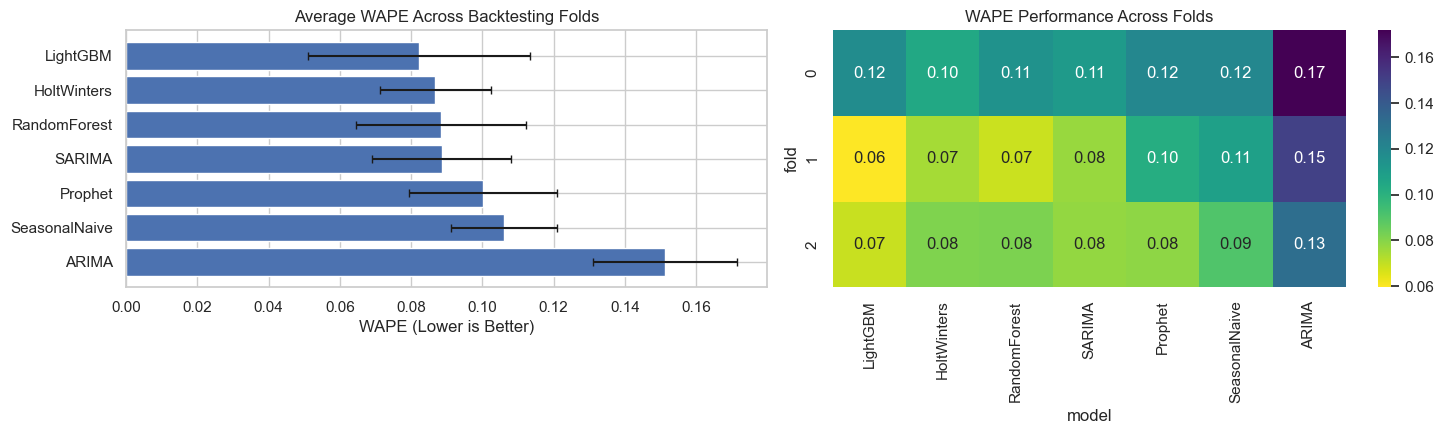

Best model by mean WAPE: LightGBM


In [69]:

# ==========================================
# 1. CALCULATE PERFORMANCE FOR EACH MODEL
# ==========================================

fold_results = []

# Group predictions by model and backtesting fold
for (model_name, fold_number), group in bt.groupby(["model", "fold"]):

    # Calculate performance metrics
    result = metrics(
        group["actual"],
        group["forecast"]
    )

    # Store the results
    result["model"] = model_name
    result["fold"] = fold_number

    fold_results.append(result)


# Convert results into a DataFrame
fold_m = pd.DataFrame(fold_results)


# ==========================================
# 2. CALCULATE AVERAGE MODEL PERFORMANCE
# ==========================================

comparison = (
    fold_m.groupby("model")
    .agg(
        WAPE=("WAPE", "mean"),
        WAPE_std=("WAPE", "std"),
        Bias=("Bias", "mean"),
        MAE=("MAE", "mean"),
        RMSE=("RMSE", "mean"),
        sMAPE=("sMAPE", "mean")
    )
    .sort_values("WAPE")
)


# ==========================================
# 3. COMPARE AGAINST SEASONAL NAIVE
# ==========================================

# Get the average WAPE of the baseline model
baseline_wape = comparison.loc["SeasonalNaive", "WAPE"]

# Calculate improvement over Seasonal Naive
comparison["WAPE_improvement_vs_SeasonalNaive"] = (
    (baseline_wape - comparison["WAPE"]) / baseline_wape
)


# ==========================================
# 4. ADD MODEL EXECUTION TIME
# ==========================================

comparison["runtime_s"] = pd.Series(runtime)

# Convert model names from index into a normal column
comparison = comparison.reset_index()


# ==========================================
# 5. DISPLAY THE MODEL COMPARISON TABLE
# ==========================================

display(
    comparison.style.format({
        "WAPE": "{:.2%}",
        "WAPE_std": "{:.2%}",
        "Bias": "{:+.2%}",
        "MAE": "{:.1f}",
        "RMSE": "{:.1f}",
        "sMAPE": "{:.2%}",
        "WAPE_improvement_vs_SeasonalNaive": "{:+.1%}",
        "runtime_s": "{:.0f}"
    })
)


# ==========================================
# 6. VISUALIZE MODEL PERFORMANCE
# ==========================================

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))


# Chart 1: Average WAPE for each model
sorted_models = comparison.sort_values("WAPE", ascending=False)

ax[0].barh(
    sorted_models["model"],
    sorted_models["WAPE"],
    xerr=sorted_models["WAPE_std"].fillna(0),
    capsize=3
)

ax[0].set_title("Average WAPE Across Backtesting Folds")
ax[0].set_xlabel("WAPE (Lower is Better)")


# Chart 2: WAPE for each model across folds
fold_pivot = fold_m.pivot(
    index="fold",
    columns="model",
    values="WAPE"
)

# Arrange model columns according to their overall ranking
fold_pivot = fold_pivot[comparison["model"]]

sns.heatmap(
    fold_pivot,
    annot=True,
    fmt=".2f",
    cmap="viridis_r",
    ax=ax[1]
)

ax[1].set_title("WAPE Performance Across Folds")


# Display both charts
plt.tight_layout()
plt.show()


# ==========================================
# 7. IDENTIFY THE BEST MODEL
# ==========================================

best_model = comparison.iloc[0]["model"]

print("Best model by mean WAPE:", best_model)


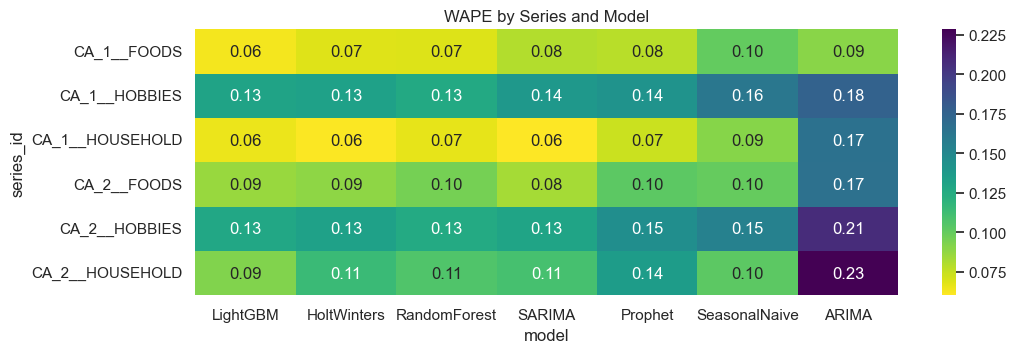

model,LightGBM,HoltWinters,RandomForest,SARIMA,Prophet,SeasonalNaive,ARIMA
h_bucket,,,,,,,
1-7,8.43%,7.74%,9.44%,8.10%,9.53%,7.58%,14.75%
15-21,10.26%,10.70%,10.76%,10.59%,12.15%,13.54%,16.91%
22-28,8.54%,8.29%,8.34%,8.19%,9.81%,10.64%,16.07%
8-14,5.40%,7.94%,6.71%,8.41%,8.40%,10.60%,12.58%


Best-performing model for each series:


,series_id,model,WAPE
0,CA_1__FOODS,LightGBM,0.063259
1,CA_1__HOBBIES,RandomForest,0.126612
2,CA_1__HOUSEHOLD,SARIMA,0.060119
3,CA_2__FOODS,SARIMA,0.083038
4,CA_2__HOBBIES,RandomForest,0.126023
5,CA_2__HOUSEHOLD,LightGBM,0.092180


In [72]:

# 1. CALCULATE WAPE FOR EACH SERIES AND MODEL

series_results = []

for (series_name, model_name), group in bt.groupby(["series_id", "model"]):

    # Calculate evaluation metrics
    result = metrics(group["actual"], group["forecast"])

    result["series_id"] = series_name
    result["model"] = model_name

    series_results.append(result)

per_series = pd.DataFrame(series_results)


# 2. PLOT WAPE FOR EACH SERIES AND MODEL

series_pivot = per_series.pivot(
    index="series_id",
    columns="model",
    values="WAPE"
)

# Keep models in the same order as the overall comparison
series_pivot = series_pivot[comparison["model"]]

plt.figure(figsize=(11, max(3, 0.45 * S + 1)))

sns.heatmap(
    series_pivot,
    annot=True,
    fmt=".2f",
    cmap="viridis_r"
)

plt.title("WAPE by Series and Model")
plt.tight_layout()
plt.show()


# 3. GROUP FORECAST HORIZONS

bt["h_bucket"] = pd.cut(
    bt["h"],
    bins=[0, 7, 14, 21, 28],
    labels=["1-7", "8-14", "15-21", "22-28"]
)


# 4. CALCULATE WAPE FOR EACH HORIZON GROUP

horizon_results = []

for (horizon, model_name), group in bt.groupby(
    ["h_bucket", "model"],
    observed=True
):

    score = wape(group["actual"], group["forecast"])

    horizon_results.append({
        "h_bucket": horizon,
        "model": model_name,
        "WAPE": score
    })

horizon_table = pd.DataFrame(horizon_results)

# Convert the results into a comparison table
horizon_table = horizon_table.pivot(
    index="h_bucket",
    columns="model",
    values="WAPE"
)

horizon_table = horizon_table[comparison["model"]]

display(
    horizon_table.style
    .format("{:.2%}")
    .set_caption("WAPE by Forecast Horizon Bucket (Days Ahead)")
)


# 5. IDENTIFY THE BEST MODEL FOR EACH SERIES

# Find the row containing the lowest WAPE for each series
best_indices = per_series.groupby("series_id")["WAPE"].idxmin()

# Extract the winning model and its WAPE
winners = per_series.loc[
    best_indices,
    ["series_id", "model", "WAPE"]
]

print("Best-performing model for each series:")

display(winners.reset_index(drop=True))


## Error Analysis


 LightGBM - Weekday performance


,WAPE,Bias,n
dow,,,
Monday,5.78%,-1.37%,72
Tuesday,6.41%,+0.10%,72
Wednesday,6.80%,+1.53%,72
Thursday,7.56%,+2.23%,72
Friday,7.13%,+1.74%,72
Saturday,9.51%,+0.16%,72
Sunday,11.40%,-4.19%,72



 LightGBM - Event vs normal days


,WAPE,Bias,n
event_day,,,
Event day,12.27%,-6.85%,42
Normal day,7.72%,+0.42%,462



 LightGBM - SNAP vs non-SNAP days


,WAPE,Bias,n
snap_day,,,
No SNAP,8.61%,-0.17%,324
SNAP day,7.30%,-0.35%,180



 LightGBM - Series performance (worst first)


,WAPE,Bias,n
series_id,,,
CA_1__HOBBIES,13.05%,-0.31%,84
CA_2__HOBBIES,12.82%,-3.66%,84
CA_2__HOUSEHOLD,9.22%,+1.81%,84
CA_2__FOODS,8.60%,-0.55%,84
CA_1__HOUSEHOLD,6.49%,+3.72%,84
CA_1__FOODS,6.33%,-1.48%,84



Ten days with the largest total absolute error:


,Total Absolute Error
date,
2016-03-20,4119.025858
2016-03-19,3581.961076
2016-03-27,2493.771626
2016-05-01,2141.791256
2016-03-26,1751.515643
2016-05-15,1393.273191
2016-04-30,1338.554941
2016-03-04,1307.961065
2016-03-25,1293.300535


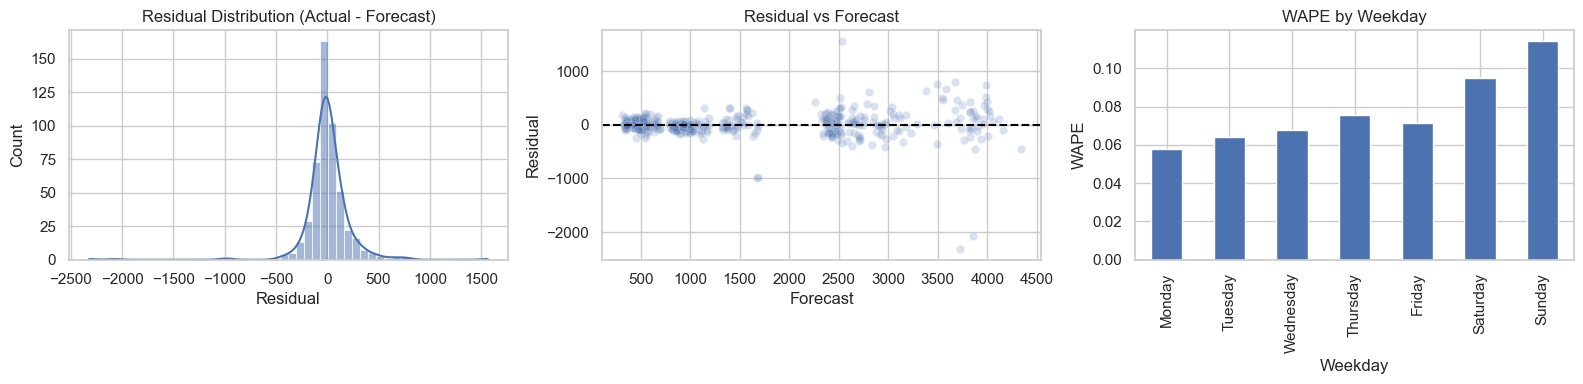

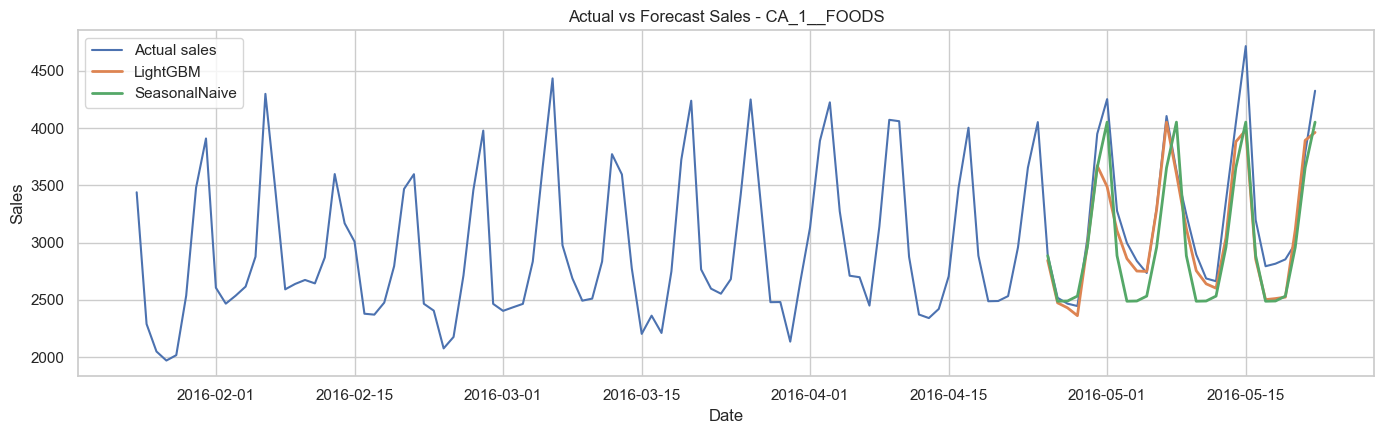

In [78]:

# ============================================================
# 1. SELECT THE BEST MODEL
# ============================================================

# Keep only predictions from the best-performing model
best_results = bt[bt["model"] == best_model].copy()

# Calculate the day of the week
best_results["dow"] = best_results["date"].dt.day_name()

# Identify normal days and event days
event_mapping = pd.Series(EV, index=cal_dates)

best_results["event_day"] = (
    best_results["date"]
    .map(event_mapping)
    .map({0: "Normal day", 1: "Event day"})
)

# Add SNAP information
snap_data = SNAP_df.stack().reset_index()

snap_data.columns = ["date", "series_id", "snap"]

best_results = best_results.merge(
    snap_data,
    on=["date", "series_id"],
    how="left"
)

best_results["snap_day"] = best_results["snap"].map({
    0: "No SNAP",
    1: "SNAP day"
})

# Calculate forecast error
# Positive error = overprediction
# Negative error = underprediction
best_results["error"] = (
    best_results["forecast"] - best_results["actual"]
)


# ============================================================
# 2. CREATE A FUNCTION TO CALCULATE ERROR METRICS
# ============================================================

def calculate_segment_metrics(group):

    actual_values = group["actual"]
    predicted_values = group["forecast"]

    total_error = group["error"].sum()

    total_actual = actual_values.sum()

    return pd.Series({

        "WAPE": wape(actual_values, predicted_values),

        "Bias": total_error / max(total_actual, 1e-9),

        "n": len(group)

    })


# ============================================================
# 3. ANALYSE ERROR BY DIFFERENT CATEGORIES
# ============================================================

# Calculate weekday performance
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_results = (
    best_results
    .groupby("dow")
    .apply(calculate_segment_metrics)
    .reindex(weekday_order)
)

# Calculate event-day performance
event_results = (
    best_results
    .groupby("event_day")
    .apply(calculate_segment_metrics)
)

# Calculate SNAP-day performance
snap_results = (
    best_results
    .groupby("snap_day")
    .apply(calculate_segment_metrics)
)

# Calculate performance for each series
series_results = (
    best_results
    .groupby("series_id")
    .apply(calculate_segment_metrics)
    .sort_values("WAPE", ascending=False)
)


# ============================================================
# 4. DISPLAY ERROR ANALYSIS RESULTS
# ============================================================

results_to_display = [

    ("Weekday performance", weekday_results),

    ("Event vs normal days", event_results),

    ("SNAP vs non-SNAP days", snap_results),

    ("Series performance (worst first)", series_results)

]

for title, result_table in results_to_display:

    print("\n", best_model, "-", title)

    display(
        result_table.style.format({

            "WAPE": "{:.2%}",

            "Bias": "{:+.2%}",

            "n": "{:.0f}"

        })
    )


# ============================================================
# 5. IDENTIFY THE TEN WORST FORECASTING DAYS
# ============================================================

# Calculate absolute error for each prediction
best_results["absolute_error"] = best_results["error"].abs()

# Calculate total absolute error for every date
worst_days = (
    best_results
    .groupby("date")["absolute_error"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTen days with the largest total absolute error:")

display(
    worst_days.to_frame("Total Absolute Error")
)


# ============================================================
# 6. VISUALIZE FORECAST ERRORS
# ============================================================

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# Plot 1: Residual distribution
sns.histplot(
    -best_results["error"],
    bins=50,
    kde=True,
    ax=ax[0]
)

ax[0].set_title("Residual Distribution (Actual - Forecast)")
ax[0].set_xlabel("Residual")


# Plot 2: Residuals against forecast values
sns.scatterplot(
    x=best_results["forecast"],
    y=-best_results["error"],
    alpha=0.2,
    ax=ax[1]
)

ax[1].axhline(
    0,
    color="black",
    linestyle="--"
)

ax[1].set_title("Residual vs Forecast")
ax[1].set_xlabel("Forecast")
ax[1].set_ylabel("Residual")


# Plot 3: WAPE by weekday
weekday_results["WAPE"].plot.bar(ax=ax[2])

ax[2].set_title("WAPE by Weekday")
ax[2].set_ylabel("WAPE")
ax[2].set_xlabel("Weekday")


plt.tight_layout()
plt.show()


# ============================================================
# 7. COMPARE ACTUAL SALES WITH FORECASTS
# ============================================================

# Find the series with the highest total historical sales
selected_series = Y.sum().idxmax()

# Select the latest backtesting fold
latest_fold = bt["fold"].max()

# Get the last 120 days of actual sales
historical_sales = Y[selected_series].iloc[-120:]

# Create the plot
plt.figure(figsize=(14, 4.5))

plt.plot(
    historical_sales.index,
    historical_sales.values,
    label="Actual sales",
    linewidth=1.5
)


# Compare the best model and Seasonal Naive
for model_name in [best_model, "SeasonalNaive"]:

    model_data = bt[
        (bt["model"] == model_name) &
        (bt["series_id"] == selected_series) &
        (bt["fold"] == latest_fold)
    ]

    plt.plot(
        model_data["date"],
        model_data["forecast"],
        label=model_name,
        linewidth=2
    )


plt.title(
    f"Actual vs Forecast Sales - {selected_series}"
)

plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()

plt.tight_layout()
plt.show()


## Forcasting 28th Day

Final 28-day sales forecast:


,series_id,date,forecast_units,model
0,CA_1__FOODS,2016-05-23,3208.994673,LightGBM
1,CA_1__FOODS,2016-05-24,2648.261870,LightGBM
2,CA_1__FOODS,2016-05-25,2625.218184,LightGBM
3,CA_1__FOODS,2016-05-26,2599.343553,LightGBM
4,CA_1__FOODS,2016-05-27,3196.949176,LightGBM
5,CA_1__FOODS,2016-05-28,3729.135193,LightGBM
6,CA_1__FOODS,2016-05-29,3914.446300,LightGBM
7,CA_1__FOODS,2016-05-30,3240.830905,LightGBM
8,CA_1__FOODS,2016-05-31,2647.263649,LightGBM
9,CA_1__FOODS,2016-06-01,3105.246646,LightGBM


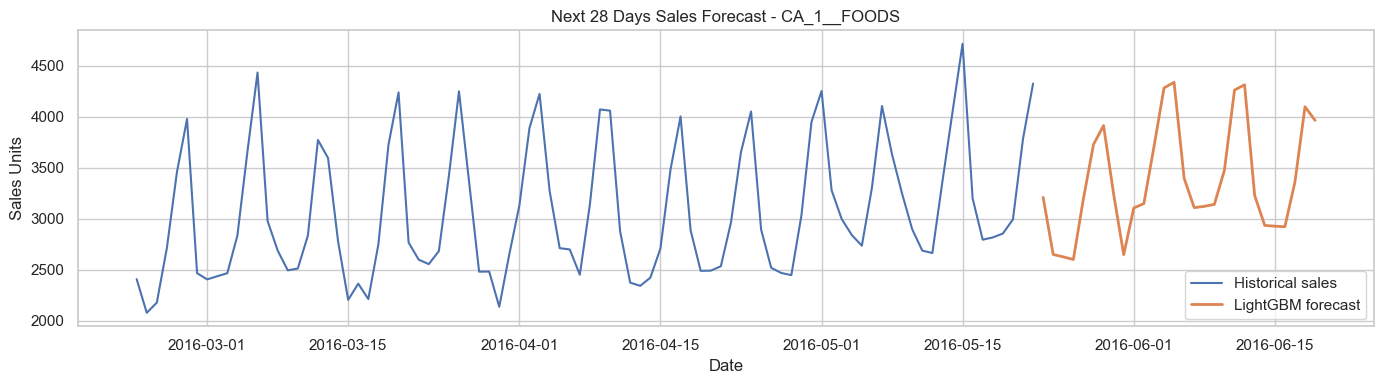

In [81]:

# ============================================================
# 1. GENERATE FINAL 28-DAY FORECAST
# ============================================================

# Use the latest available historical date
final_origin = T - 1

# Generate predictions using the best model
predictions = predict_model(
    best_model,
    final_origin
)

# Get dates for the next 28 days
future_dates = cal_dates[T:T + HORIZON]


# ============================================================
# 2. CREATE THE FINAL FORECAST TABLE
# ============================================================

forecast_results = []

for series_position, series_id in enumerate(series_ids):

    series_forecast = pd.DataFrame({

        "series_id": series_id,

        "date": future_dates,

        "forecast_units": predictions[series_position],

        "model": best_model

    })

    forecast_results.append(series_forecast)


# Combine all series forecasts
future = pd.concat(
    forecast_results,
    ignore_index=True
)


# Display forecast results
print("Final 28-day sales forecast:")

display(future.head(10))


# ============================================================
# 3. VISUALIZE HISTORICAL AND FUTURE SALES
# ============================================================

# Select the series with the highest historical sales
selected_series = Y.sum().idxmax()

# Get the last 90 days of historical sales
historical_sales = Y[selected_series].iloc[-90:]

# Get forecast values for the selected series
future_sales = future[
    future["series_id"] == selected_series
]

# Plot historical sales
plt.figure(figsize=(14, 4))

plt.plot(
    historical_sales.index,
    historical_sales.values,
    label="Historical sales"
)

# Plot future forecast
plt.plot(
    future_sales["date"],
    future_sales["forecast_units"],
    label=f"{best_model} forecast",
    linewidth=2
)

plt.title(
    f"Next 28 Days Sales Forecast - {selected_series}"
)

plt.xlabel("Date")
plt.ylabel("Sales Units")

plt.legend()

plt.tight_layout()
plt.show()


In [83]:
print("Best model:", best_model)
print("Prediction shape:", predictions.shape)
print("Future dates:", len(future_dates))
print("Forecast table shape:", future.shape)

Best model: LightGBM
Prediction shape: (6, 28)
Future dates: 28
Forecast table shape: (168, 4)
